# Projet 12 - Détection de faux billets
## ONCFM - Organisation nationale de lutte contre le faux-monnayage

Ce notebook a pour objectif de construire un algorithme capable de différencier
les vrais des faux billets à partir de leurs caractéristiques géométriques.

# 1) Chargement des données

In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "billets.csv"

df = pd.read_csv(DATA_PATH, sep=";")
print("Donnees chargees :", df.shape)
df.head()

Donnees chargees : (1500, 7)


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
dtypes: bool(1), float64(6)
memory usage: 71.9 KB


# 2) Analyse exploratoire (EDA)

Objectifs de cette section :
- comprendre la structure et la qualite des donnees (valeurs manquantes, types)
- observer la repartition vrai / faux billets
- identifier les variables les plus discriminantes pour la suite (modelisation)

In [32]:
print("Repartition vrai / faux billets :")
print(df["is_genuine"].value_counts())
print()
print("Proportion :")
print(df["is_genuine"].value_counts(normalize=True).round(3))

Repartition vrai / faux billets :
is_genuine
True     1000
False     500
Name: count, dtype: int64

Proportion :
is_genuine
True     0.667
False    0.333
Name: proportion, dtype: float64


Le dataset est desequilibre : 1000 vrais billets (66,7%) contre 500 faux billets (33,3%).
Il faudra en tenir compte lors de l'interpretation des metriques d'evaluation :
une accuracy elevee ne suffit pas, il faudra regarder specifiquement le recall
sur la classe "faux billet".

In [33]:
print("Valeurs manquantes par colonne :")
df.isna().sum()

Valeurs manquantes par colonne :


is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

In [34]:
# Les valeurs manquantes sont-elles liees a la nature du billet (vrai/faux) ?
missing = df[df["margin_low"].isna()]
print("Repartition des lignes avec margin_low manquant :")
print(missing["is_genuine"].value_counts())
print()
print("Proportion de faux billets dans tout le dataset       :", round((df["is_genuine"] == False).mean(), 3))
print("Proportion de faux billets parmi les valeurs manquantes:", round((missing["is_genuine"] == False).mean(), 3))

Repartition des lignes avec margin_low manquant :
is_genuine
True     29
False     8
Name: count, dtype: int64

Proportion de faux billets dans tout le dataset       : 0.333
Proportion de faux billets parmi les valeurs manquantes: 0.216


Les 37 valeurs manquantes sur `margin_low` ne semblent pas liees particulierement
aux faux billets (21,6% de faux parmi les manquants, contre 33,3% dans le dataset
complet). Rien n'indique un lien entre le fait d'avoir cette valeur manquante et la
nature du billet : on peut donc imputer ces valeurs sans craindre d'introduire de
biais vis-a-vis de la cible.

In [35]:
df.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1500.000000,1500.000000,1500.000000,1463.000000,1500.000000,1500.00000
mean,171.958440,104.029533,103.920307,4.485967,3.151473,112.67850
std,0.305195,0.299462,0.325627,0.663813,0.231813,0.87273
min,171.040000,103.140000,102.820000,2.980000,2.270000,109.49000
25%,171.750000,103.820000,103.710000,4.015000,2.990000,112.03000
50%,171.960000,104.040000,103.920000,4.310000,3.140000,112.96000
75%,172.170000,104.230000,104.150000,4.870000,3.310000,113.34000
max,173.010000,104.880000,104.950000,6.900000,3.910000,114.44000


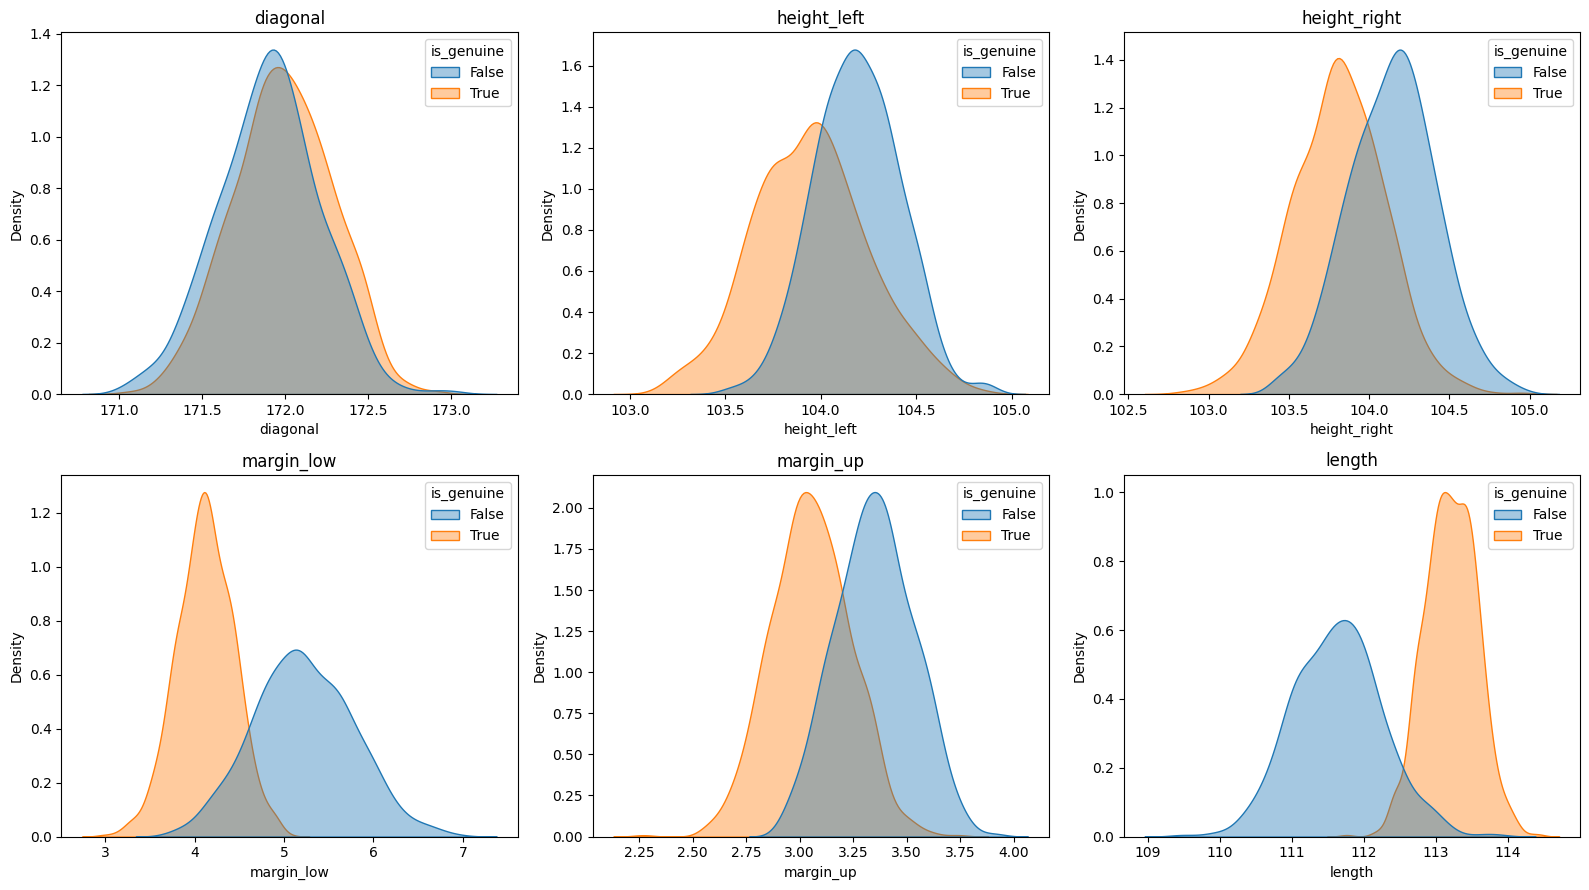

In [36]:
cols = ["diagonal", "height_left", "height_right", "margin_low", "margin_up", "length"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(cols):
    sns.kdeplot(data=df, x=col, hue="is_genuine", ax=axes[i], fill=True, common_norm=False, alpha=0.4)
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

In [37]:
df["target"] = df["is_genuine"].astype(int)
corr_target = df[cols + ["target"]].corr()["target"].drop("target").sort_values(key=abs, ascending=False)
print("Correlation de chaque variable avec la cible (is_genuine) :")
print(corr_target)
df.drop(columns="target", inplace=True)

Correlation de chaque variable avec la cible (is_genuine) :
length          0.849285
margin_low     -0.783032
margin_up      -0.606262
height_right   -0.485092
height_left    -0.379833
diagonal        0.132756
Name: target, dtype: float64


**Lecture des resultats :**

| Variable | Correlation avec la cible | Pouvoir discriminant |
|---|---|---|
| length | 0.85 | tres fort |
| margin_low | -0.78 | fort |
| margin_up | -0.61 | fort |
| height_right | -0.49 | modere |
| height_left | -0.38 | modere |
| diagonal | 0.13 | tres faible |

`length`, `margin_low` et `margin_up` sont les variables les plus discriminantes :
les vrais billets sont plus longs et ont des marges plus petites que les faux.
`diagonal` apporte tres peu d'information a elle seule, mais on la conserve : elle
pourra etre utile en combinaison avec les autres variables, notamment pour le
Random Forest.

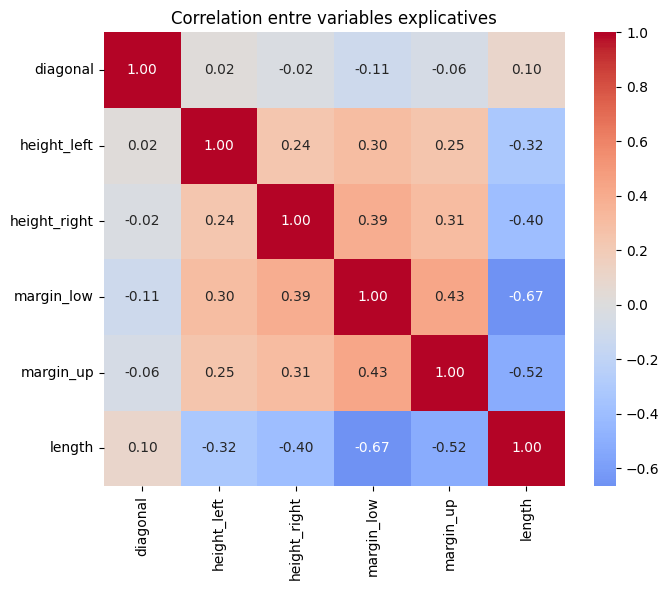

In [38]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation entre variables explicatives")
plt.tight_layout()
plt.show()

Aucune paire de variables n'est fortement redondante (toutes les correlations entre
variables explicatives restent sous 0.7 en valeur absolue). On garde donc les 6
variables pour la modelisation, sans en exclure aucune pour cause de
multicolinearite.

## 2.5) Analyse en Composantes Principales (ACP)

L'ACP permet de resumer les 6 variables geometriques en un plus petit
nombre de composantes (combinaisons lineaires des variables d'origine),
et de visualiser comment chaque variable contribue a la separation des
billets.

Note : cette ACP est purement exploratoire (elle sert a mieux comprendre
la structure des donnees), elle n'intervient pas dans le pipeline de
modelisation. Pour ce calcul uniquement, on retire les 37 lignes avec
`margin_low` manquant plutot que de les imputer (l'ACP necessite des
donnees completes, et il ne s'agit ici que d'exploration, pas
d'entrainement d'un modele).

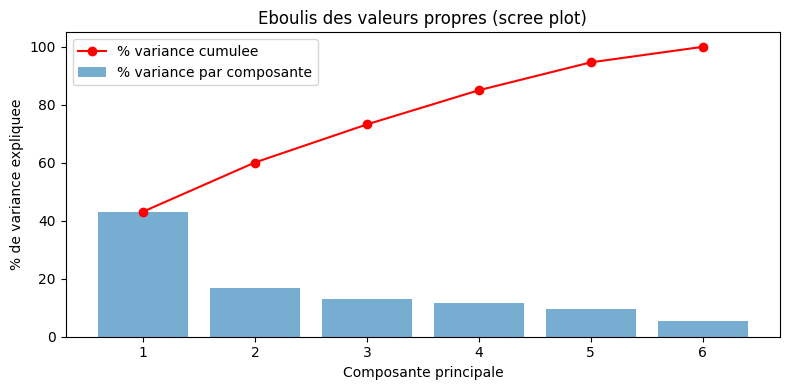

Variance expliquee par composante (%) : [43.1 17.  13.1 11.8  9.6  5.4]
Variance cumulee (2 premieres composantes) : 60.1 %


In [39]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df_pca = df.dropna(subset=["margin_low"])
X_pca_data = df_pca[cols]

scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_data)

pca_eda = PCA(n_components=6, random_state=42)
pca_eda.fit(X_pca_scaled)

plt.figure(figsize=(8, 4))
plt.bar(range(1, 7), pca_eda.explained_variance_ratio_ * 100, alpha=0.6, label="% variance par composante")
plt.plot(range(1, 7), pca_eda.explained_variance_ratio_.cumsum() * 100, color="red", marker="o", label="% variance cumulee")
plt.xlabel("Composante principale")
plt.ylabel("% de variance expliquee")
plt.title("Eboulis des valeurs propres (scree plot)")
plt.legend()
plt.tight_layout()
plt.show()

print("Variance expliquee par composante (%) :", (pca_eda.explained_variance_ratio_ * 100).round(1))
print("Variance cumulee (2 premieres composantes) :", round(pca_eda.explained_variance_ratio_[:2].sum() * 100, 1), "%")

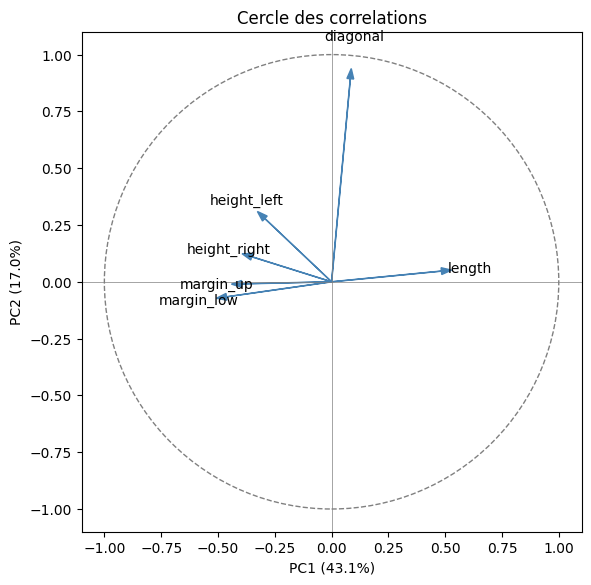

In [40]:
fig, ax = plt.subplots(figsize=(6, 6))
for i, col in enumerate(cols):
    ax.arrow(0, 0, pca_eda.components_[0, i], pca_eda.components_[1, i],
              head_width=0.03, length_includes_head=True, color="steelblue")
    ax.text(pca_eda.components_[0, i] * 1.15, pca_eda.components_[1, i] * 1.15, col,
             ha="center", va="center", fontsize=10)

circle = plt.Circle((0, 0), 1, facecolor="none", edgecolor="grey", linestyle="--")
ax.add_patch(circle)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel(f"PC1 ({pca_eda.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca_eda.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Cercle des correlations")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**Lecture des resultats :**

- Les 2 premieres composantes expliquent 60,1% de la variance totale (43,1%
  pour PC1, 17,0% pour PC2). Il faut 5 composantes pour depasser 90%, donc
  l'ACP resume utilement les donnees sans toutefois les reduire de facon
  drastique a 2 dimensions seulement.
- **PC1** est portee principalement par `length` (+0,53), `margin_low`
  (-0,51), `margin_up` (-0,44), `height_right` (-0,39) et `height_left`
  (-0,33) : c'est quasiment le meme axe que celui qui separe les vrais des
  faux billets (vu en correlation avec la cible plus haut). `diagonal`
  (+0,09) ne contribue presque pas a PC1.
- **PC2** est presque exclusivement portee par `diagonal` (+0,94) : cette
  variable est quasiment independante de l'axe qui distingue vrai/faux,
  ce qui confirme, par une methode differente, ce que l'analyse des
  correlations avait deja montre (`diagonal` est peu discriminante).

# 3) Pretraitement

Le but est de transformer les donnees brutes en donnees exploitables par les
algorithmes de Machine Learning, en respectant un point de vigilance essentiel :
**eviter toute fuite de donnees (data leakage)**. Concretement, toute etape qui
"apprend" quelque chose des donnees (imputation, standardisation) doit etre
calibree uniquement sur le jeu d'entrainement, puis appliquee telle quelle au jeu
de test.

### 3.1) Separation des variables explicatives et de la cible

X = les mesures du billet (longueur, hauteur, diagonale, marges)

y = l'etiquette (vrai ou faux)

In [41]:
X = df.drop(columns="is_genuine")
y = df["is_genuine"]

print("X :", X.shape)
print("y :", y.shape)

X : (1500, 6)
y : (1500,)


### 3.2) Separation train / test

On separe les donnees en un jeu d'entrainement (80%) et un jeu de test (20%),
avec `stratify=y` pour conserver la meme proportion de vrais/faux billets dans
les deux sous-ensembles. Cette separation est faite **avant** l'imputation et la
standardisation, pour que ces etapes ne soient calibrees que sur le train.

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape, " Test :", X_test.shape)
print("Valeurs manquantes dans le train :", X_train["margin_low"].isna().sum())
print("Valeurs manquantes dans le test  :", X_test["margin_low"].isna().sum())

Train : (1200, 6)  Test : (300, 6)
Valeurs manquantes dans le train : 25
Valeurs manquantes dans le test  : 12


### 3.3) Imputation des valeurs manquantes (`margin_low`)

Plusieurs approches sont possibles pour traiter les 37 valeurs manquantes :

1. **Suppression des lignes** : simple, mais fait perdre 2,5% des donnees
   alors que l'information est en grande partie recuperable.
2. **Imputation par une valeur constante** (moyenne ou mediane) : rapide,
   mais ignore les liens entre `margin_low` et les autres variables du
   billet, ce qui ecrase la variabilite naturelle des mesures.
3. **Imputation par une methode de machine learning** (regression lineaire,
   KNNImputer, etc.) : utilise la correlation entre `margin_low` et les
   autres variables pour estimer une valeur plus precise qu'avec une
   constante.

On retient l'option 3, avec **KNNImputer** de scikit-learn : pour chaque
valeur manquante, il repere les billets les plus proches (sur les autres
variables disponibles) et moyenne leur `margin_low`. C'est une classe
standard fournie directement par scikit-learn, ce qui simplifie le
pipeline final (pas besoin de coder ni de maintenir une classe
d'imputation personnalisee).

Comme pour la standardisation, l'imputeur est calibre uniquement sur le
train (`fit_transform`), puis applique tel quel au test (`transform`
seul). On verifie ensuite que l'imputation ne deforme pas la distribution
de `margin_low`.

In [43]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test), columns=X_test.columns, index=X_test.index
)

print("Valeurs manquantes restantes - train :", X_train_imputed["margin_low"].isna().sum())
print("Valeurs manquantes restantes - test  :", X_test_imputed["margin_low"].isna().sum())

Valeurs manquantes restantes - train : 0
Valeurs manquantes restantes - test  : 0


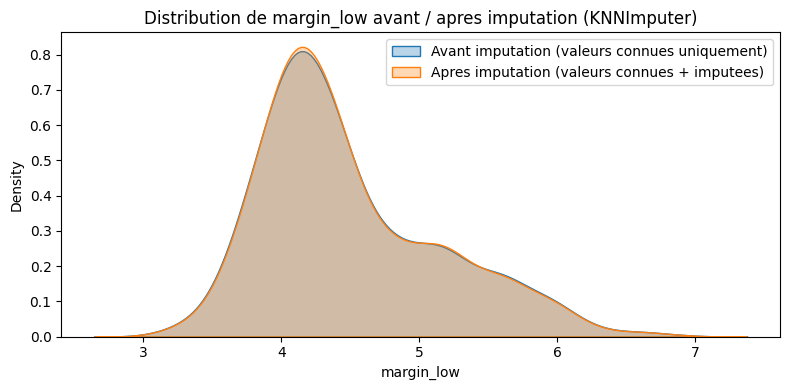

Moyenne     - avant : 4.491  apres : 4.49
Ecart-type  - avant : 0.656  apres : 0.652


In [44]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(X_train["margin_low"].dropna(), label="Avant imputation (valeurs connues uniquement)", ax=ax, fill=True, alpha=0.3)
sns.kdeplot(X_train_imputed["margin_low"], label="Apres imputation (valeurs connues + imputees)", ax=ax, fill=True, alpha=0.3)
ax.set_title("Distribution de margin_low avant / apres imputation (KNNImputer)")
ax.legend()
plt.tight_layout()
plt.show()

print("Moyenne     - avant :", round(X_train["margin_low"].mean(), 3), " apres :", round(X_train_imputed["margin_low"].mean(), 3))
print("Ecart-type  - avant :", round(X_train["margin_low"].std(), 3), " apres :", round(X_train_imputed["margin_low"].std(), 3))

La distribution de `margin_low` apres imputation se superpose presque
parfaitement a la distribution d'origine (moyenne et ecart-type quasi
identiques). L'imputation par KNNImputer n'a donc pas deforme la variable,
contrairement a ce qu'aurait pu faire une imputation par une valeur
constante (qui aurait cree un pic artificiel autour de la mediane).

### 3.4) Standardisation

On met toutes les variables sur la meme echelle (moyenne = 0, ecart-type = 1).
C'est indispensable pour la regression logistique, le KNN et le K-means, qui sont
sensibles aux differences d'echelle entre variables (sans cela, `length`, qui varie
entre 109 et 114, ecraserait `margin_low`, qui varie entre 3 et 7).

Comme pour l'imputation, le `StandardScaler` est calibre uniquement sur le train
(`fit_transform`), puis applique tel quel au test (`transform` seul).

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imputed), columns=X_train_imputed.columns, index=X_train_imputed.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imputed), columns=X_test_imputed.columns, index=X_test_imputed.index
)

print("Moyennes (train, doivent etre ~0) :")
print(X_train_scaled.mean().round(3))
print()
print("Ecarts-types (train, doivent etre ~1) :")
print(X_train_scaled.std().round(3))

Moyennes (train, doivent etre ~0) :
diagonal        0.0
height_left    -0.0
height_right    0.0
margin_low      0.0
margin_up       0.0
length         -0.0
dtype: float64

Ecarts-types (train, doivent etre ~1) :
diagonal        1.0
height_left     1.0
height_right    1.0
margin_low      1.0
margin_up       1.0
length          1.0
dtype: float64


# 4) Modelisation

On met en concurrence quatre methodes de prediction, comme demande dans le cahier
des charges :
- Regression logistique
- KNN
- Random Forest
- K-means (algorithme non supervise, adapte a la classification via ses centroides)

On stocke les predictions et probabilites de chaque modele dans un dictionnaire
`results`, pour pouvoir les comparer proprement dans la section suivante.

In [46]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

results = {}  # stocke y_pred et y_proba de chaque modele pour comparaison ulterieure

## 4.0) Comprendre les metriques d'evaluation

Avant de comparer les modeles, voici ce que mesure chaque metrique
utilisee dans les sections suivantes :

- **Matrice de confusion** : tableau qui croise la prediction du modele
  et la realite. Elle affiche 4 cases : vrais positifs, faux negatifs,
  faux positifs et vrais negatifs (le detail depend de quelle classe on
  considere comme "positive" ; ici on s'interesse surtout aux faux
  billets non detectes et aux vrais billets rejetes a tort).
- **Accuracy** : proportion de predictions correctes sur l'ensemble des
  billets. Simple a lire, mais trompeuse sur un dataset desequilibre
  (ici 1000 vrais pour 500 faux) : un modele qui predirait toujours
  "vrai" aurait deja 66,7% d'accuracy sans rien detecter.
- **Precision (sur la classe Faux)** : parmi tous les billets que le
  modele a predits comme faux, quelle proportion l'est reellement. Une
  precision faible signifie que le modele rejette trop de vrais billets
  a tort (fausses alertes).
- **Recall / rappel (sur la classe Faux)** : parmi tous les faux billets
  reellement presents, quelle proportion le modele arrive a detecter.
  **C'est la metrique la plus importante ici**, puisque le cahier des
  charges demande explicitement d'identifier un maximum de faux billets :
  un recall faible signifie que des faux billets passent inapercus.
- **F1-score** : moyenne harmonique de la precision et du recall, utile
  pour resumer les deux en une seule valeur quand aucune des deux n'est
  a privilegier de facon absolue.

## 4.1) Regression logistique

Principe : la regression logistique cherche une combinaison lineaire des variables
qu'elle transforme ensuite via une fonction sigmoide pour obtenir une probabilite
d'appartenance a la classe "vrai billet". C'est un bon candidat ici car l'EDA a
montre une separation quasi lineaire entre vrais et faux billets sur plusieurs
variables (`length`, `margin_low`, `margin_up`).

Parametre ajuste : `max_iter=1000`, pour laisser suffisamment d'iterations a
l'algorithme d'optimisation pour converger (la valeur par defaut de 100 est parfois
trop faible).

Accuracy : 0.99

              precision    recall  f1-score   support

       False       0.99      0.98      0.98       100
        True       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



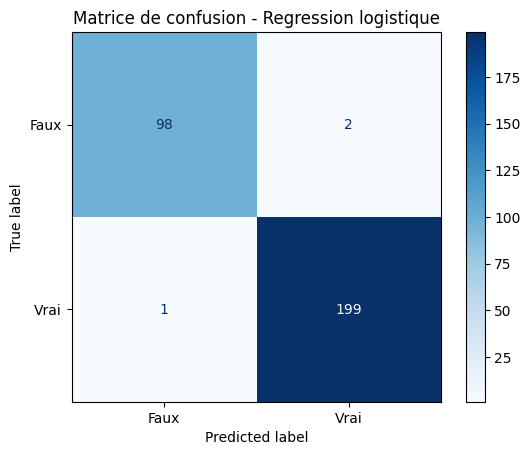

In [47]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)

y_pred_logreg = logreg.predict(X_test_scaled)
y_proba_logreg = logreg.predict_proba(X_test_scaled)[:, 1]

results["Regression logistique"] = {"y_pred": y_pred_logreg, "y_proba": y_proba_logreg}

print("Accuracy :", round((y_pred_logreg == y_test).mean(), 4))
print()
print(classification_report(y_test, y_pred_logreg))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_logreg), display_labels=["Faux", "Vrai"]).plot(cmap="Blues")
plt.title("Matrice de confusion - Regression logistique")
plt.show()

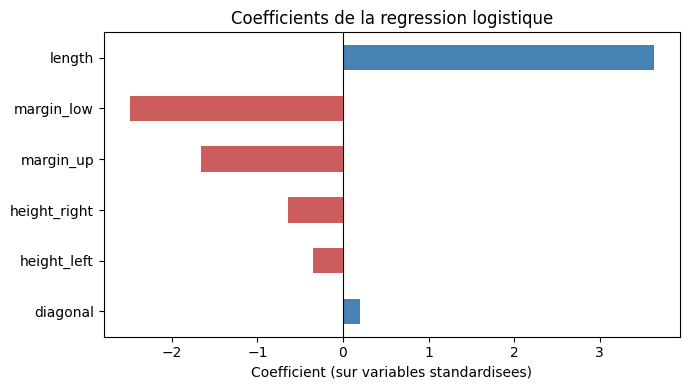

length          3.630853
margin_low     -2.489117
margin_up      -1.653733
height_right   -0.637708
height_left    -0.352469
diagonal        0.193619
dtype: float64

In [48]:
coefficients = pd.Series(logreg.coef_[0], index=X_train_scaled.columns).sort_values(key=abs, ascending=False)

plt.figure(figsize=(7, 4))
colors = ["indianred" if c < 0 else "steelblue" for c in coefficients]
coefficients.plot(kind="barh", color=colors)
plt.gca().invert_yaxis()
plt.xlabel("Coefficient (sur variables standardisees)")
plt.title("Coefficients de la regression logistique")
plt.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

coefficients

**Lecture des coefficients :** les variables etant standardisees, le signe
et l'amplitude de chaque coefficient indiquent directement son influence
sur la probabilite qu'un billet soit vrai.

- `length` (+3.63) : coefficient positif le plus fort. Plus un billet est
  long (par rapport a la moyenne), plus la probabilite qu'il soit vrai
  augmente.
- `margin_low` (-2.49) et `margin_up` (-1.65) : coefficients negatifs.
  Plus les marges sont grandes, plus la probabilite d'etre vrai diminue
  (les faux billets ont des marges plus grandes, coherent avec l'EDA).
- `height_right` (-0.64) et `height_left` (-0.35) : effet negatif plus
  modere.
- `diagonal` (+0.19) : quasiment nul, confirme une nouvelle fois que
  cette variable n'aide presque pas a distinguer vrai et faux.

Ce classement est le meme que celui trouve avec les correlations en EDA
et avec l'importance des variables du Random Forest (section 4.3) : 3
methodes independantes convergent vers la meme conclusion, ce qui
renforce la confiance dans ces resultats.

## 4.2) KNN (K-Nearest Neighbors)

Principe : contrairement a la regression logistique, le KNN n'apprend pas de
formule. Il memorise le jeu d'entrainement, et pour predire un nouveau billet, il
regarde ses K voisins les plus proches (distance euclidienne, calculee sur les
variables standardisees) et prend la classe majoritaire parmi eux.

Le parametre cle est **K** (n_neighbors) :
- K trop petit -> modele sensible au bruit, risque de sur-apprentissage
- K trop grand -> frontieres trop lissees, risque de sous-apprentissage

Pour une classification binaire, on evite de preference un K pair (risque
d'egalite parfaite entre les deux classes parmi les voisins).

**Modifiez `k_range` ci-dessous pour tester d'autres valeurs.**

K= 1  accuracy=0.9867
K= 2  accuracy=0.9867
K= 3  accuracy=0.9867
K= 4  accuracy=0.9867
K= 5  accuracy=0.9833
K= 6  accuracy=0.9867
K= 7  accuracy=0.9867
K= 8  accuracy=0.9867
K= 9  accuracy=0.9867
K=10  accuracy=0.9900
K=11  accuracy=0.9900
K=12  accuracy=0.9933
K=13  accuracy=0.9867
K=14  accuracy=0.9900
K=15  accuracy=0.9900


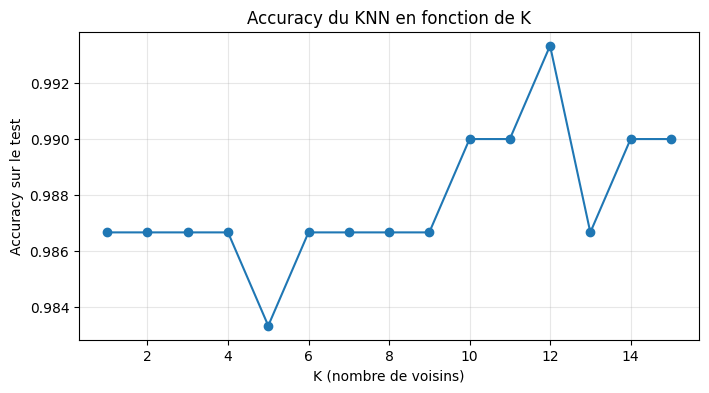

In [49]:
from sklearn.neighbors import KNeighborsClassifier

k_range = range(1, 16)  # <-- modifiable : tester d'autres plages de K
accuracies = []

for k in k_range:
    knn_test = KNeighborsClassifier(n_neighbors=k)
    knn_test.fit(X_train_scaled, y_train)
    y_pred_k = knn_test.predict(X_test_scaled)
    accuracies.append((y_pred_k == y_test).mean())

for k, acc in zip(k_range, accuracies):
    print(f"K={k:2d}  accuracy={acc:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(list(k_range), accuracies, marker="o")
plt.xlabel("K (nombre de voisins)")
plt.ylabel("Accuracy sur le test")
plt.title("Accuracy du KNN en fonction de K")
plt.grid(alpha=0.3)
plt.show()

**Choix retenu : K=11.**

Toutes les valeurs de K entre 1 et 15 donnent des resultats tres proches (98,3%
a 99,3%), ce qui est coherent avec la bonne separation des classes observee en
EDA. K=12 obtient le meilleur score sur ce decoupage precis, mais un K pair
comporte un risque d'egalite de vote entre les deux classes. On retient donc
K=11 (impair, score quasi identique) plutot que de choisir uniquement sur la
base du score le plus eleve, qui pourrait aussi refleter le hasard de ce
decoupage train/test plutot qu'un reel avantage.

Accuracy : 0.99

              precision    recall  f1-score   support

       False       0.99      0.98      0.98       100
        True       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



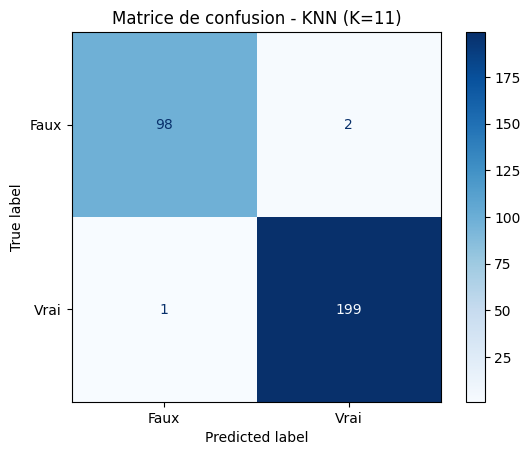

In [50]:
knn = KNeighborsClassifier(n_neighbors=11)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]

results["KNN"] = {"y_pred": y_pred_knn, "y_proba": y_proba_knn}

print("Accuracy :", round((y_pred_knn == y_test).mean(), 4))
print()
print(classification_report(y_test, y_pred_knn))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn), display_labels=["Faux", "Vrai"]).plot(cmap="Blues")
plt.title("Matrice de confusion - KNN (K=11)")
plt.show()

## 4.3) Random Forest

Principe : le Random Forest est un modele d'ensemble. Il entraine plusieurs
centaines d'arbres de decision, chacun sur un sous-echantillon aleatoire des
donnees et un sous-ensemble aleatoire des variables a chaque split. La
prediction finale est la classe majoritaire votee par tous les arbres.

Cette approche reduit le sur-apprentissage typique d'un arbre de decision
unique : les erreurs individuelles de chaque arbre ont tendance a s'annuler
en votant ensemble.

A la difference du KNN et de la regression logistique, la standardisation
n'est pas necessaire pour le Random Forest (il raisonne par seuils sur chaque
variable independamment). On reutilise neanmoins X_train_scaled par
coherence avec les autres modeles.

Parametres : n_estimators=200 (nombre d'arbres), random_state=42 pour la
reproductibilite.

Accuracy : 0.99

              precision    recall  f1-score   support

       False       0.99      0.98      0.98       100
        True       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



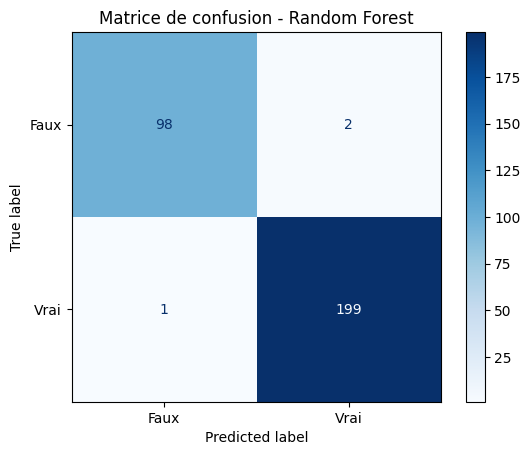

In [51]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
y_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

results["Random Forest"] = {"y_pred": y_pred_rf, "y_proba": y_proba_rf}

print("Accuracy :", round((y_pred_rf == y_test).mean(), 4))
print()
print(classification_report(y_test, y_pred_rf))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf), display_labels=["Faux", "Vrai"]).plot(cmap="Blues")
plt.title("Matrice de confusion - Random Forest")
plt.show()

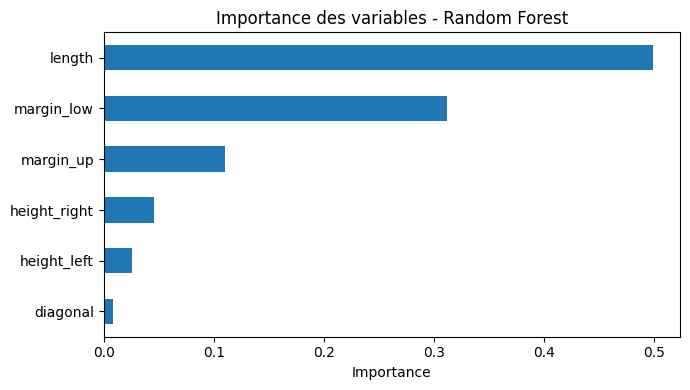

length          0.498403
margin_low      0.311609
margin_up       0.110203
height_right    0.045860
height_left     0.025884
diagonal        0.008041
dtype: float64

In [52]:
importances = pd.Series(rf.feature_importances_, index=X_train_scaled.columns).sort_values(ascending=False)

plt.figure(figsize=(7, 4))
importances.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Importance des variables - Random Forest")
plt.tight_layout()
plt.show()

importances

Le Random Forest obtient 99% d'accuracy, avec la meme matrice de confusion
que la regression logistique (2 faux billets classes vrais a tort, 1 vrai
classe faux a tort). L'importance des variables confirme l'analyse faite en
EDA : length (49,8%) et margin_low (31,0%) portent a elles seules pres de
81% de la decision du modele, tandis que diagonal ne pese quasiment rien
(0,8%).

## 4.4) K-means

Le K-means est different des 3 modeles precedents : c'est un algorithme non
supervise. Il ne connait pas les etiquettes vrai/faux pendant l'entrainement,
il regroupe seulement les billets en clusters selon leurs similarites
geometriques.

Etapes suivies :
1. Entrainer K-means avec K=2 sur X_train_scaled (sans utiliser y_train)
2. Etablir la correspondance cluster -> label en regardant, apres coup, la
   composition majoritaire de chaque cluster
3. Predire sur le test, remapper les clusters vers vrai/faux, puis evaluer
4. Evaluer la forme des clusters (silhouette score) et les caracteriser
   visuellement (projection PCA)

Composition des clusters (train) :
is_genuine  False  True 
row_0                   
0             388      7
1              12    793

Correspondance cluster -> label : {0: np.False_, 1: np.True_}

Accuracy : 0.9867

              precision    recall  f1-score   support

       False       0.98      0.98      0.98       100
        True       0.99      0.99      0.99       200

    accuracy                           0.99       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.99      0.99      0.99       300



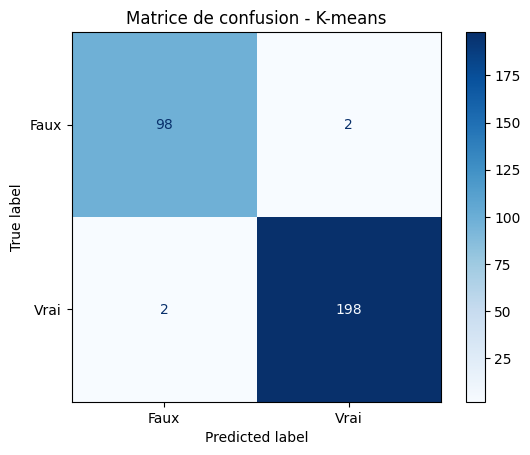

Silhouette score : 0.345


In [53]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train_scaled)

# Composition de chaque cluster (etiquettes utilisees seulement pour interpreter,
# jamais pour l'entrainement du clustering)
comp = pd.crosstab(train_clusters, y_train)
print("Composition des clusters (train) :")
print(comp)

# Correspondance cluster -> label, basee sur la majorite
cluster_to_label = {c: comp.loc[c].idxmax() for c in [0, 1]}
print("\nCorrespondance cluster -> label :", cluster_to_label)

# Prediction sur le test
test_clusters = kmeans.predict(X_test_scaled)
y_pred_kmeans = pd.Series(test_clusters).map(cluster_to_label).values

results["K-means"] = {"y_pred": y_pred_kmeans, "y_proba": None}

print("\nAccuracy :", round((y_pred_kmeans == y_test.values).mean(), 4))
print()
print(classification_report(y_test, y_pred_kmeans))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_kmeans), display_labels=["Faux", "Vrai"]).plot(cmap="Blues")
plt.title("Matrice de confusion - K-means")
plt.show()

sil = silhouette_score(X_train_scaled, train_clusters)
print("Silhouette score :", round(sil, 3))

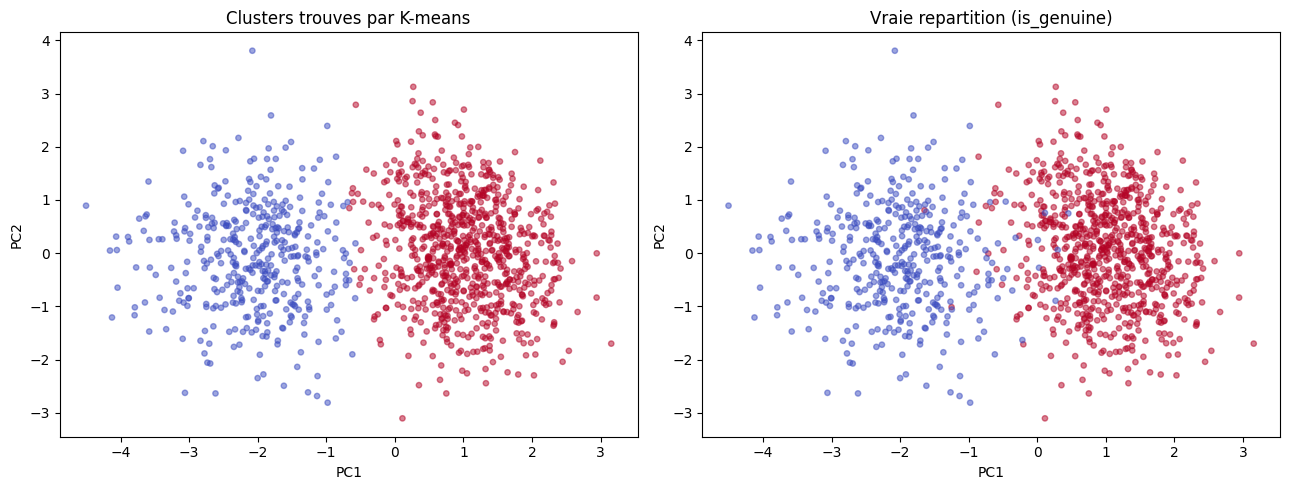

Variance expliquee par les 2 composantes : 0.603


In [54]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_clusters, cmap="coolwarm", alpha=0.5, s=15)
axes[0].set_title("Clusters trouves par K-means")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

axes[1].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train.astype(int), cmap="coolwarm", alpha=0.5, s=15)
axes[1].set_title("Vraie repartition (is_genuine)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

print("Variance expliquee par les 2 composantes :", round(pca.explained_variance_ratio_.sum(), 3))

Sans jamais voir les etiquettes pendant l'entrainement, le K-means retrouve
quasiment la vraie repartition vrai/faux : 98,67% d'accuracy sur le test,
tres proche des 3 modeles supervises. Le silhouette score de 0,345 indique
une separation correcte mais pas parfaite des clusters, coherent avec le
chevauchement observe en EDA sur diagonal et les variables de hauteur.

La projection PCA (60,4% de variance expliquee par les 2 composantes)
confirme visuellement que les clusters trouves par K-means correspondent
presque exactement a la vraie nature des billets : les rares erreurs se
situent a la frontiere entre les deux nuages de points.

Le K-means est donc pertinent pour cette etude : la structure des donnees
est suffisamment marquee pour qu'un algorithme non supervise retrouve, par
lui-meme, une distinction tres proche de la verite terrain.

# 5) Selection du meilleur modele

Le critere de choix ne doit pas etre uniquement l'accuracy globale : le
cahier des charges demande explicitement d'identifier un maximum de faux
billets. On privilegie donc le recall sur la classe "Faux" (capacite a ne
pas laisser passer un faux billet), en plus des autres metriques standards.

In [55]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

preds = {
    "Regression logistique": y_pred_logreg,
    "KNN (K=11)": y_pred_knn,
    "Random Forest": y_pred_rf,
    "K-means": y_pred_kmeans,
}

rows = []
for name, y_pred in preds.items():
    cm = confusion_matrix(y_test, y_pred)
    rows.append({
        "Modele": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision (Faux)": round(precision_score(y_test, y_pred, pos_label=False), 4),
        "Recall (Faux)": round(recall_score(y_test, y_pred, pos_label=False), 4),
        "F1 (Faux)": round(f1_score(y_test, y_pred, pos_label=False), 4),
        "Faux billets non detectes (FN)": cm[0][1],
        "Vrais billets rejetes a tort (FP)": cm[1][0],
    })

comparison = pd.DataFrame(rows).sort_values("Recall (Faux)", ascending=False)
comparison

,Modele,Accuracy,Precision (Faux),Recall (Faux),F1 (Faux),Faux billets non detectes (FN),Vrais billets rejetes a tort (FP)
0,Regression logistique,0.9900,0.9899,0.98,0.9849,2,1
1,KNN (K=11),0.9900,0.9899,0.98,0.9849,2,1
2,Random Forest,0.9900,0.9899,0.98,0.9849,2,1
3,K-means,0.9867,0.9800,0.98,0.9800,2,2


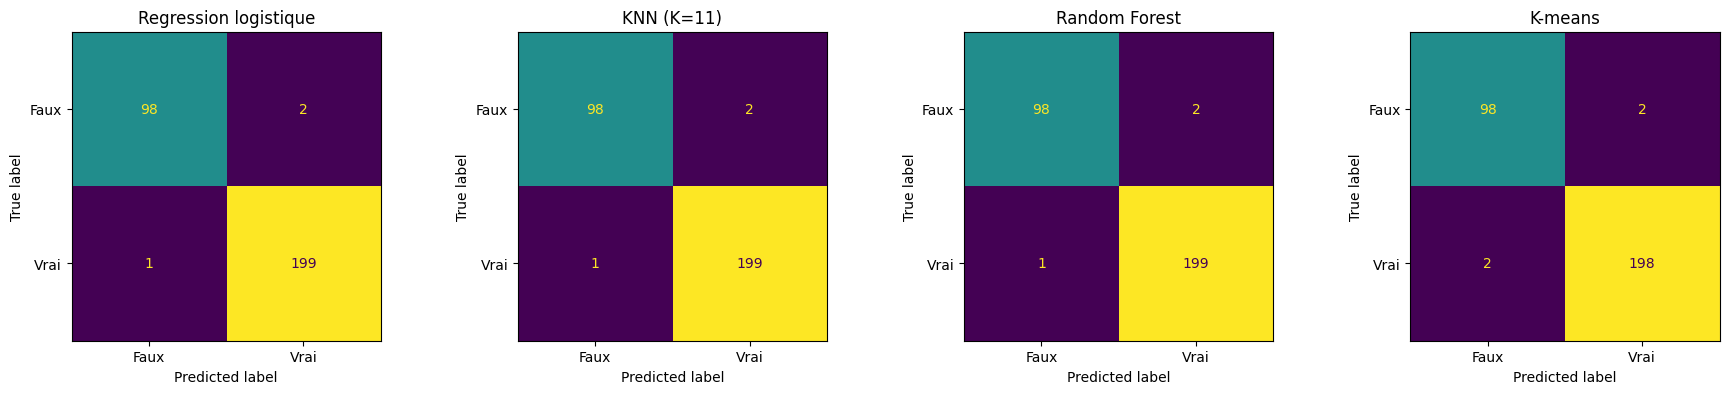

In [56]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Faux", "Vrai"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [57]:
errors_logreg = set(X_test.index[y_pred_logreg != y_test.values])
errors_knn = set(X_test.index[y_pred_knn != y_test.values])
errors_rf = set(X_test.index[y_pred_rf != y_test.values])

common_errors = errors_logreg & errors_knn & errors_rf
print("Billets mal classes par les 3 modeles supervises :", common_errors)
df.loc[list(common_errors)]

Billets mal classes par les 3 modeles supervises : {728, 1160, 1190}


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
728,True,171.94,104.11,104.16,4.08,3.35,111.76
1160,False,172.39,104.05,104.32,4.13,3.41,112.66
1190,False,171.45,104.21,104.18,4.55,3.52,113.21


**Modele retenu : Regression logistique.**

Les 3 modeles supervises (regression logistique, KNN, Random Forest)
obtiennent des performances identiques (accuracy 0,99, recall Faux 0,98),
et se trompent exactement sur les 3 memes billets du jeu de test. Cela
indique que ces erreurs proviennent de cas ambigus dans les donnees
elles-memes (mesures proches de la frontiere vrai/faux), plutot que
d'une faiblesse propre a un algorithme.

Le K-means, bien que non supervise, obtient un score tres proche
(accuracy 0,9867), ce qui confirme la bonne separabilite naturelle des
donnees.

Entre les 3 modeles a egalite de performance, on retient la **regression
logistique** plutot que le Random Forest, pour les raisons suivantes :
- performance strictement identique (memes 3 erreurs, meme recall)
- modele beaucoup plus simple : une seule formule lineaire, contre 200
  arbres de decision pour le Random Forest
- **interpretabilite directe** via les coefficients (section 4.1) : on
  peut expliquer a l'ONCFM, en une phrase, pourquoi un billet est juge
  faux ("le billet est trop court et ses marges sont trop grandes"), ce
  qui est plus parlant qu'une importance de variables agregee sur 200
  arbres
- plus leger et plus rapide a entrainer et a utiliser en production

Le Random Forest reste un tres bon candidat de secours (memes
performances, potentiellement plus robuste face a des relations non
lineaires dans de futures donnees), mais pour ce projet, la simplicite
et la transparence de la regression logistique sont jugees
preferables.

# 6) Sauvegarde du meilleur modele

Le modele final est reentraine sur l'integralite des 1500 billets (train +
test reunis), et non plus seulement sur le train. Le garde-fou train/test
n'est plus necessaire a ce stade : la performance reelle du modele a deja
ete mesuree honnetement dans la section precedente (99% accuracy, 0,98
recall). Pour la mise en production, on veut au contraire que le modele
apprenne sur un maximum de donnees, puisqu'il ne sera plus jamais reevalue
de cette facon.

Le pipeline complet (imputation + standardisation + regression logistique)
est sauvegarde avec joblib. KNNImputer, StandardScaler et
LogisticRegression etant tous des classes standard de scikit-learn, le
pipeline se recharge directement avec joblib.load, sans avoir besoin d'un
module de pretraitement separe a maintenir a cote du script de
production.

In [58]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import KNNImputer
import joblib

final_pipeline = make_pipeline(
    KNNImputer(n_neighbors=5),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

final_pipeline.fit(X, y)

joblib.dump(final_pipeline, "model_faux_billets.joblib")
print("Modele sauvegarde : model_faux_billets.joblib")

Modele sauvegarde : model_faux_billets.joblib


---

Le chargement du modele sauvegarde et la demonstration de son
fonctionnement sur de nouvelles donnees (fichier CSV et billet unique)
sont regroupes dans un second notebook, livre a part :
**`p12_faux_billets_demonstration.ipynb`**.